# 07. Pyomo and jaxglobal, side by side

This series writes the same optimization problems twice: once as a [Pyomo](https://www.pyomo.org) model [hart2011pyomo, bynum2021pyomo], and once as a plain Python/JAX function for jaxglobal,
a global optimizer that traces the function and bounds it with McCormick/alphaBB relaxations inside a branch-and-bound [mccormick1976computability]. Every notebook solves both and
compares objective, certified bound, time and status. The audience is chemical engineers and optimization researchers who already know one of the two styles.

The comparison is meant to be fair. Pyomo has a large ecosystem, mature global solvers (SCIP, BARON, Couenne here), logical (GDP) modelling, duals,
named constraints and sparse large-scale structure. jaxglobal is a research solver for continuous and integer variables; these notebooks use only continuous ones. Where Pyomo is faster or more capable, the notebooks say so.

| Notebook | Topic |
|---|---|
| 08-pyomo-basics | Six-hump camel function; Haverly pooling problem |
| 09-control-flow | `where`, `clip`, `max`, `interp`: pipe flow regimes and steam tables; Pyomo GDP and `Piecewise` |
| 10-ode-models | Kinetic parameter estimation with an ODE; explicit RK4 and `pyomo.dae` |
| 11-neural-network-surrogates | Minimizing a trained tanh MLP; hand-written Pyomo and OMLT |
| 12-things-pyomo-cannot-express | `fori_loop`, library functions, einsum, parametric families |
| 13-many-switches | Motor price lists as one `jnp.where`: when many switches favor jaxglobal, and when they do not |

**Conditions.** All solvers use relative gap 1e-4 (absolute 1e-6) and at most 60 s per solve (300 s in 13). Timings are wall-clock on the machine that ran the notebooks and include
the model-writing time for Pyomo solvers and JIT compilation for jaxglobal; treat them as rough. All data are either published problem data or synthetic (labeled in each notebook).

**Reading the tables.** `obj` is the best objective found, `bound` the certified lower bound the solver reports (NaN means the solver did not return one;
Couenne does not through the `.nl` interface), `status` the solver's termination.

**References.** Citation keys in square brackets refer to entries in `docs/references.bib` at the repository root.

## Two ways to state the same problem

Every notebook in this part solves a problem of the form

$$
\min_{x \in [x^L, x^U]} f(x) \quad \text{s.t.} \quad g(x) \le 0,\ h(x) = 0 ,
$$

and both tools prove a global optimum the same way, by spatial branch and bound: on each box $B$ they compute a lower bound $L(B) \le \min_{x \in B} f(x)$
from a convex relaxation, keep the best feasible point found so far as the upper bound $U$, and split or discard boxes until $U - \min_B L(B)$ is below the
tolerance. The result is a certificate $L \le f^* \le U$ [mccormick1976computability]. They differ in what the solver is given.

* **Pyomo** builds the problem as an expression tree of variables, parameters and a fixed set of operators. Pyomo writes it to a file (`.nl` for SCIP and
  Couenne, `.gms` for BARON through GAMS), and the solver relaxes each operator in that tree. Anything outside the operator set (a loop, a library call, a
  `where`) must first be rewritten as equations, usually with auxiliary variables $w = \phi(x)$ and, for logic, binaries.
* **jaxglobal** is given the Python function itself. `jax.make_jaxpr` traces it into a flat list of JAX primitives, and every primitive has a relaxation rule:
  McCormick's for products and compositions, $\alpha$BB, $\check f(x) = f(x) - \tfrac{\alpha}{2}\sum_i (x_i - x_i^L)(x_i^U - x_i)$, for smooth functions
  without a known envelope. The relaxation of the whole function is again a JAX function, so it is compiled and evaluated on hundreds of boxes at once.
  Notebooks 01 and 02 explain both steps in detail.

The diagram shows the two routes.

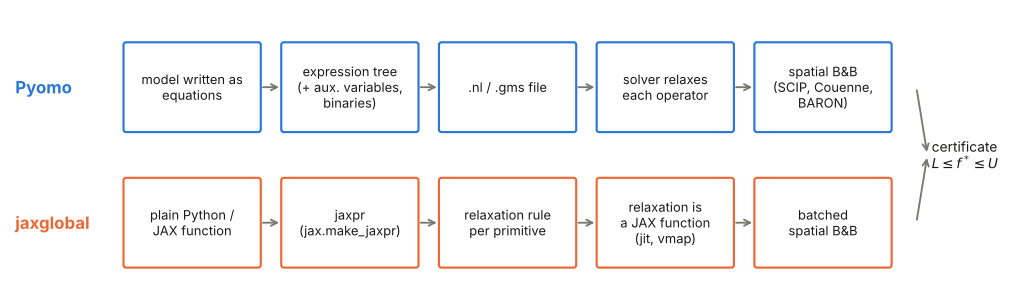

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

INK, MUTED, BLUE, ORANGE, AQUA, YELLOW = "#1a1a19", "#77766f", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6, "figure.dpi": 110})  # fmt: skip
SOLVER_COLOR = {"scip": BLUE, "couenne": AQUA, "baron": YELLOW, "jaxglobal": ORANGE}  # as in notebooks 08-12

fig, ax = plt.subplots(figsize=(11.5, 3.2))
ax.set_xlim(0, 11.5), ax.set_ylim(0, 3.2), ax.axis("off")
rows = [
    (2.3, "Pyomo", BLUE, ["model written as\nequations", "expression tree\n(+ aux. variables,\nbinaries)", ".nl / .gms file", "solver relaxes\neach operator", "spatial B&B\n(SCIP, Couenne,\nBARON)"]),
    (0.7, "jaxglobal", ORANGE, ["plain Python /\nJAX function", "jaxpr\n(jax.make_jaxpr)", "relaxation rule\nper primitive", "relaxation is\na JAX function\n(jit, vmap)", "batched\nspatial B&B"]),
]
for y, name, col, steps in rows:
    ax.text(0.05, y, name, ha="left", va="center", fontsize=11, color=col, weight="bold")
    for k, label in enumerate(steps):
        x = 1.35 + 1.85 * k
        ax.add_patch(FancyBboxPatch((x, y - 0.5), 1.55, 1.0, boxstyle="round,pad=0.03", fc="white", ec=col, lw=1.4))
        ax.text(x + 0.775, y, label, ha="center", va="center", fontsize=8.5, color=INK)
        if k:
            ax.annotate("", (x - 0.02, y), (x - 0.28, y), arrowprops=dict(arrowstyle="->", color=MUTED, lw=1.2))
for y in (2.3, 0.7):
    ax.annotate("", (10.75, 1.5), (10.62, y), arrowprops=dict(arrowstyle="->", color=MUTED, lw=1.2))
ax.text(10.8, 1.5, "certificate\n$L \\leq f^* \\leq U$", ha="left", va="center", fontsize=9, color=INK)
plt.show()

## Counting lines of model code

"Lines of model code" is measured by one helper, `nbutil.loc`, which takes the functions that make up a model and counts source lines excluding blanks, comments and docstrings.
Its source:

In [2]:
import inspect
import json
import os

import numpy as np
import pandas as pd

import nbutil
from nbutil import loc

print(inspect.getsource(loc))

def loc(*objs):
    """Count lines of model code: source lines minus blank lines, comments and docstrings."""
    n = 0
    for o in objs:
        src = inspect.getsource(o)
        src = re.sub(r'("""|\'\'\')(.*?)\1', "", src, flags=re.S)  # drop docstrings
        n += sum(1 for ln in src.splitlines() if ln.strip() and not ln.strip().startswith("#"))
    return n



## Results of all comparisons

Filled in from the results saved by notebooks 08 to 13 (`notebooks/results/*.json`). Run those notebooks first.
Model size is the Pyomo model's unfixed variables and active constraints (the jaxglobal model has no explicit constraints beyond optional `ineq`/`eq` functions).

In [3]:
here = os.path.dirname(os.path.abspath(nbutil.__file__))
NAMES = {"08": "08-pyomo-basics", "09": "09-control-flow", "10": "10-ode-models", "11": "11-neural-network-surrogates", "12": "12-things-pyomo-cannot-express", "13": "13-many-switches"}
cases = []
for nb in sorted(NAMES):
    path = os.path.join(here, "results", f"{nb}.json")
    if os.path.exists(path):
        for case, d in json.load(open(path)).items():
            cases.append((NAMES[nb], case, d))
print(f"{len(cases)} comparisons from {len({c[0] for c in cases})} notebooks")

13 comparisons from 6 notebooks


In [4]:
size_rows = [
    {
        "notebook": nb,
        "case": case,
        "loc Pyomo": d["loc_pyomo"],
        "loc jaxglobal": d["loc_jax"],
        "Pyomo vars": d["pyomo_vars"],
        "Pyomo constraints": d["pyomo_cons"],
    }
    for nb, case, d in cases
]
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
pd.DataFrame(size_rows).fillna("n/a")

,notebook,case,loc Pyomo,loc jaxglobal,Pyomo vars,Pyomo constraints
0,08-pyomo-basics,six-hump camel,8.0,3.0,2.0,0.0
1,08-pyomo-basics,Haverly pooling,19.0,9.0,9.0,6.0
2,09-control-flow,"A: pipe (where, clip)",28.0,11.0,14.0,16.0
3,09-control-flow,"B: steam tables (interp, max)",15.0,11.0,33.0,32.0
4,10-ode-models,RK4 kinetics (explicit),24.0,14.0,10.0,8.0
5,10-ode-models,pyomo.dae (collocation),16.0,14.0,52.0,50.0
6,11-neural-network-surrogates,tanh MLP 2-8-8-1 (reduced space),11.0,2.0,2.0,0.0
7,11-neural-network-surrogates,tanh MLP 2-8-8-1 (full space),19.0,2.0,34.0,32.0
8,12-things-pyomo-cannot-express,Colebrook fori_loop,11.0,10.0,3.0,1.0
9,12-things-pyomo-cannot-express,library functions,n/a,n/a,n/a,n/a


Pyomo needs more lines in most cases, partly because it must declare variables, bounds and constraints that a function does not need. The line count says little about
solver quality, and model sizes are for the Pyomo formulation only.

In [5]:
res_rows = []
for nb, case, d in cases:
    for r in d["rows"]:
        res_rows.append({"notebook": nb[:2], "case": case, "solver": r["solver"], "obj": r["obj"], "bound": r["bound"], "time (s)": round(r["time"], 2) if r["time"] == r["time"] else np.nan, "status": r["status"]})
df = pd.DataFrame(res_rows)
df.style.format({"obj": "{:.6g}", "bound": "{:.6g}"}, na_rep="n/a").hide(axis="index")

notebook,case,solver,obj,bound,time (s),status
08,six-hump camel,scip,-1.03163,-1.03171,0.200000,optimal
08,six-hump camel,couenne,-1.03163,n/a,0.220000,optimal
08,six-hump camel,baron,n/a,n/a,n/a,not run: GAMS/BARON not installed
08,six-hump camel,jaxglobal,-1.03163,-1.03169,1.140000,optimal
08,six-hump camel,"jaxglobal (2nd call, cached)",-1.03163,-1.03169,0.200000,optimal
08,Haverly pooling,scip,-400,-400,0.060000,optimal
08,Haverly pooling,couenne,-400,n/a,0.250000,optimal
08,Haverly pooling,baron,n/a,n/a,n/a,not run: GAMS/BARON not installed
08,Haverly pooling,jaxglobal,-400,-400.002,2.380000,optimal
09,"A: pipe (where, clip)",scip,-2828.74,-2828.95,0.590000,optimal


### The comparisons at a glance

Three views of the same table. **Lines of model code**: each point is one case; points above the diagonal need more Pyomo code than JAX code.
**Wall time**: one marker per solver and case, on a log scale; hollow markers did not reach the gap tolerance within the time limit. **Agreement**: how far each
solver's objective is from the best objective any solver found in that case, relative to its size; points at the left edge agree to the plotting floor of
$10^{-10}$. Variants of a solver (a second cached call, `crown`, a different formulation) share its color. The library-function rows of notebook 12 name
functions rather than solvers and are left out.

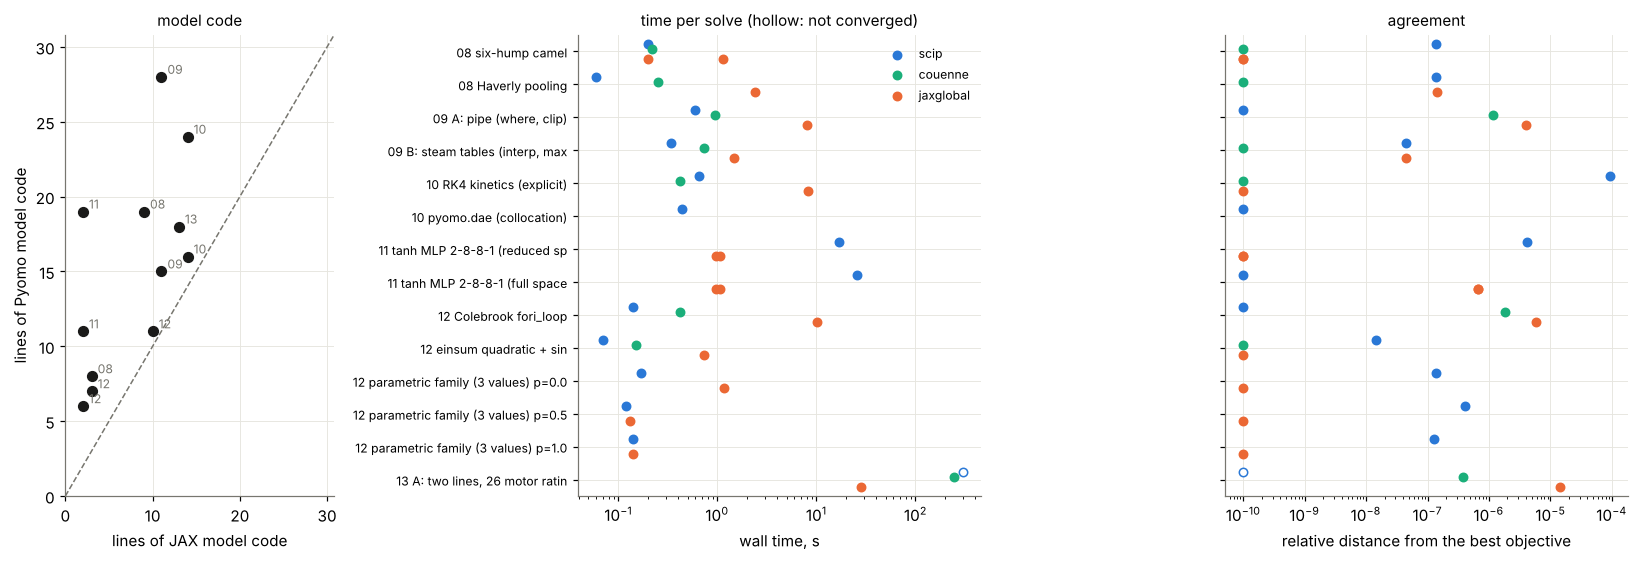

In [6]:
sizes = pd.DataFrame(size_rows).dropna(subset=["loc Pyomo", "loc jaxglobal"])
df["base"] = df["solver"].str.split().str[0]  # "scip (dae)" -> scip, "jaxglobal crown" -> jaxglobal
variant = df["solver"].str.split(n=1).str[1].fillna("")
df["label"] = df["notebook"] + " " + df["case"].str.slice(0, 28) + np.where(variant.str.startswith("p="), " " + variant, "")
df = df[df["base"].isin(SOLVER_COLOR)]  # 12's library-function rows name functions, not solvers, and are not plotted
labels = list(dict.fromkeys(df["label"]))
best = df[df["obj"] == df["obj"]].groupby("label")["obj"].min()

fig, axs = plt.subplots(1, 3, figsize=(15, 5.2), gridspec_kw=dict(width_ratios=[1, 1.5, 1.5]))
ax = axs[0]
ax.scatter(sizes["loc jaxglobal"], sizes["loc Pyomo"], s=40, color=INK, zorder=3)
m = max(sizes["loc Pyomo"].max(), sizes["loc jaxglobal"].max()) * 1.1
ax.plot([0, m], [0, m], color=MUTED, lw=1, ls="--")
for _, r in sizes.iterrows():
    ax.annotate(r["notebook"][:2], (r["loc jaxglobal"], r["loc Pyomo"]), xytext=(4, 2), textcoords="offset points", fontsize=8, color=MUTED)
ax.set_xlabel("lines of JAX model code"), ax.set_ylabel("lines of Pyomo model code"), ax.set_title("model code", fontsize=10)
ax.set_xlim(0, m), ax.set_ylim(0, m)

for ax, key in ((axs[1], "time (s)"), (axs[2], "agreement")):
    for j, (solver, col) in enumerate(SOLVER_COLOR.items()):
        d = df[(df["base"] == solver) & (df["obj"] == df["obj"])]
        if d.empty:
            continue
        yy = np.array([labels.index(l) for l in d["label"]]) + (j - 1.5) * 0.15
        if key == "time (s)":
            xx = d["time (s)"].to_numpy()
        else:
            xx = np.maximum(np.abs(d["obj"].to_numpy() - best[d["label"]].to_numpy()) / np.maximum(np.abs(best[d["label"]].to_numpy()), 1e-12), 1e-10)
        done = (d["status"] == "optimal").to_numpy()
        ax.scatter(xx[done], yy[done], color=col, s=30, label=solver, zorder=3)
        ax.scatter(xx[~done], yy[~done], facecolor="white", edgecolor=col, s=30, zorder=3)
    ax.set_xscale("log"), ax.set_yticks(range(len(labels))), ax.set_ylim(len(labels) - 0.5, -0.5)
ax = axs[1]
ax.set_yticklabels(labels, fontsize=8), ax.set_xlabel("wall time, s"), ax.set_title("time per solve (hollow: not converged)", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper right")
axs[2].set_yticklabels([]), axs[2].set_xlabel("relative distance from the best objective"), axs[2].set_title("agreement", fontsize=10)
plt.tight_layout()
plt.show()

## Summary

* **Speed.** On these small problems the Pyomo solvers usually finish first; jaxglobal's time is dominated by JIT compilation of the traced function on the
  first call, and a second solve of the same function is much faster (notebook 08). The exception is notebook 13, where a long motor price list adds binaries
  to the Pyomo model but no search dimension to jaxglobal's (see the time panel above, and the scaling study in 13).
* **Agreement.** Where both sides finish, objectives agree to the gap tolerance (agreement panel). Full-space formulations can report an objective a few
  1e-5 below the optimum, because their equations hold only to the solver's feasibility tolerance (notebook 11).
* **Where jaxglobal reads better.** Models that are numerical code: ODE integrators, neural networks, loops, library functions, vectorized algebra. There is
  no transcription step.
* **Where Pyomo is better.** Integer and logical structure, a choice of mature solvers, named constraints and duals, sparse large-scale models, and a large
  ecosystem (`pyomo.dae`, GDP, OMLT).
* **Current jaxglobal limits found while writing these notebooks.** Compile time grows quickly with the length of an unrolled loop (notebook 10);
  `jnp.interp` has no relaxation rule yet (notebook 09); `lax.scan` and fixed-count `lax.fori_loop` are unrolled like Python loops (since
  PR #81; before that they were bounded as a single iteration), and `lax.while_loop` and a `lax.cond` on a model value are refused (notebooks 10, 12).
  Python `for` loops of fixed length are always traced correctly.
* **Solvers on the machine that ran these notebooks.** BARON needs GAMS and a license; where it is missing its rows read `not run`, and the comparison rests
  on SCIP and Couenne.